# Frequency-search results explorer

Look at the output of an adversarial frequency search (`freq_search.py`): the
per-`(letter, pattern)` multipliers, the resulting per-word frequencies, and the
greedy strategy analyzed the *same way* as in `strategy_explorer` but under the
adversarial weighting (greedy playing against the adversarial word choices).

Generate a run first with e.g. `python math/freq_search.py 5` (saves to
`math/data/freq_search/len05.csv`); this notebook loads it back.

In [1]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'freq_search.py').exists():
            return c
    raise FileNotFoundError('Could not find freq_search.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import freq_search, strategy

pd.set_option('display.max_rows', 200)

print(f'imported from {math_dir}')

imported from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Load a search result

Loads the saved CSV for this length if present; otherwise runs one inline (which
can be slow for larger lengths).

In [2]:
LENGTH = 7
OBJECTIVE = 'best_opener'      # 'greedy' or 'best_opener' -- which tuned run to explore below

csv_path = freq_search._default_log_path(OBJECTIVE, LENGTH)
if csv_path.exists():
    s = freq_search.FrequencySearch.reconstruct(LENGTH, csv_path, objective=OBJECTIVE)
    print(f'loaded {OBJECTIVE} run: {csv_path.parent.name}/{csv_path.name}')
else:
    print(f'no saved run at {csv_path}\nrunning one inline (may take a while)...')
    s = freq_search.FrequencySearch(LENGTH, objective=OBJECTIVE)
    s.run(verbose=False)

game, f = s.game, s.freq
bo_letter, bo = game.best_opener_misses(f)
print(f'length {LENGTH} [{OBJECTIVE}]: {game.N} words, {s.M} patterns')
print(f'on this tuned distribution -- pure greedy {game.average_misses(f):.4f}   '
      f'best opener {bo:.4f} (via {bo_letter!r})')

loaded best_opener run: best_opener/len07.csv
length 7 [best_opener]: 5541 words, 561 patterns
on this tuned distribution -- pure greedy 4.4104   best opener 4.4051 (via 'l')


## Compare objectives: greedy-tuned vs best-opener-tuned

Load **both** adversarial runs for this length (if present) and score each tuned
distribution with **both** guessers: `greedy_avg` = pure greedy, `best_opener_avg`
= the guesser who picks the best first letter then plays greedy. A distribution
tuned only against *pure greedy* can be escaped by a smarter opener (large `gap`);
one tuned against the *best-opener* guesser leaves little room to improve (small
`gap`). Missing runs are skipped — generate them with `python math/freq_search.py
<LEN>` and `... --best-opener`.

In [3]:
def load_run(objective):
    p = freq_search._default_log_path(objective, LENGTH)
    if not p.exists():
        print(f'  (no {objective!r} run for length {LENGTH} at {p.parent.name}/{p.name})')
        return None
    return freq_search.FrequencySearch.reconstruct(LENGTH, p, objective=objective)

# score each tuned distribution with BOTH guessers
rows = []
for objective in freq_search.OBJECTIVES:
    r = load_run(objective)
    if r is None:
        continue
    gm, fr = r.game, r.freq
    greedy = gm.average_misses(fr)
    bl, bv = gm.best_opener_misses(fr)
    rows.append({'tuned_for': objective,
                 'greedy_avg': greedy, 'greedy_opener': gm.greedy_first_letter(fr),
                 'best_opener_avg': bv, 'best_opener_letter': bl,
                 'gap': greedy - bv})
pd.DataFrame(rows).set_index('tuned_for').round(4)

,greedy_avg,greedy_opener,best_opener_avg,best_opener_letter,gap
tuned_for,,,,,
greedy,4.5811,g,4.1689,t,0.4121
best_opener,4.4104,g,4.4051,l,0.0053


## Multipliers

One row per `(letter, pattern)`; `multiplier` is the tuned weight, `n_words` how
many words carry that pattern.

In [4]:
mult_df = s.multipliers_df()
print(f'{(mult_df.multiplier == 0).sum()} patterns of {len(mult_df)} zeroed; '
      f'{(mult_df.multiplier > 1).sum()} boosted above 1; '
      f'max multiplier {mult_df.multiplier.max():g}')
mult_df.head(200)

223 patterns of 561 zeroed; 51 boosted above 1; max multiplier 64


,letter,pattern,mask,multiplier,n_words
0,g,______g,64,64.000,595
1,n,_____n_,32,32.000,795
2,i,____i__,16,32.000,1031
3,y,__y____,4,8.125,63
4,f,__ff___,12,4.125,22
5,g,g___g__,17,4.000,2
6,d,d_dd___,13,4.000,1
7,n,n__n___,9,4.000,3
8,b,_____b_,32,4.000,10
9,p,p_p____,5,4.000,5


In [5]:
mult_df[mult_df['pattern'] == '____s']

,letter,pattern,mask,multiplier,n_words


In [6]:
mult_df[mult_df['pattern'].str[6] == 'g']

,letter,pattern,mask,multiplier,n_words
0,g,______g,64,64.0,595
396,g,g__g__g,73,0.0,2
433,g,g_gg__g,77,0.0,1
441,g,g_____g,65,0.0,29
478,g,___g__g,72,0.0,20
494,g,__g___g,68,0.0,5
538,g,__gg__g,76,0.0,19


In [7]:
mult_df.tail(200)

,letter,pattern,mask,multiplier,n_words
361,e,__e_e__,20,0.0,32
362,i,i__i_i_,41,0.0,3
363,i,_i_i___,10,0.0,33
364,e,__e__ee,100,0.0,1
365,n,____nn_,48,0.0,3
366,n,__nn_n_,44,0.0,17
367,e,___e_ee,104,0.0,1
368,t,_____t_,32,0.0,270
369,i,i______,1,0.0,95
370,d,__d____,4,0.0,93


## Frequencies

One row per word (frequency = product of its pattern multipliers).

In [8]:
freq_df = s.frequencies_df()
print(f'{(freq_df.frequency == 0).sum()} words of {len(freq_df)} at frequency 0 (removed); '
      f'heaviest carry the adversarial weight:')
freq_df.head(200)

5183 words of 5541 at frequency 0 (removed); heaviest carry the adversarial weight:


,word,frequency
0,rhyming,1064960.0
1,puffing,540672.0
2,huffing,540672.0
3,jerking,524288.0
4,jutting,524288.0
5,jamming,491520.0
6,jacking,491520.0
7,popping,475136.0
8,bobbing,393216.0
9,peeping,313344.0


In [9]:
sum(freq_df['frequency'])

48157312.0

In [10]:
sum(freq_df[freq_df['word'].str[-3:] == 'ing']['frequency'])

48157312.0

In [11]:
freq_df.tail(200)

,word,frequency
5341,apostle,0.0
5342,voucher,0.0
5343,veggies,0.0
5344,vaguely,0.0
5345,trimmed,0.0
5346,summons,0.0
5347,stirred,0.0
5348,starved,0.0
5349,rewrite,0.0
5350,rethink,0.0


In [12]:
freq_df.iloc[354]

word         clawing
frequency     1152.0
Name: 354, dtype: object

In [13]:
freq_df['frequency'].sum()

48157312.0

In [14]:
x = freq_df[freq_df['word'].str[-3:] == 'ing']
y = freq_df[freq_df['word'].str[-1:] == 's']
x['frequency'].sum() + y['frequency'].sum()

48157312.0

In [15]:
a = freq_df[freq_df['word'].str[-1:] == 'z']
a['frequency'].sum() / freq_df['frequency'].sum()

0.0

In [16]:
a

,word,frequency
1513,showbiz,0.0
2589,kibbutz,0.0


In [17]:
y['frequency'].sum() / freq_df['frequency'].sum()

0.0

In [18]:
z = freq_df[(freq_df['word'].str[-3:] != 'ing')]
z.head(50)

,word,frequency
358,steeply,0.0
359,smartly,0.0
360,rapport,0.0
361,busters,0.0
362,abysmal,0.0
364,violins,0.0
365,subsets,0.0
366,somatic,0.0
367,thereto,0.0
368,lacquer,0.0


In [19]:
(z['frequency'].sum()) / freq_df['frequency'].sum()

0.0

In [20]:
len(freq_df[freq_df['frequency'] > 0])

358

In [21]:
len(x) + len(y)

2112

In [22]:
freq_df.tail(200)

,word,frequency
5341,apostle,0.0
5342,voucher,0.0
5343,veggies,0.0
5344,vaguely,0.0
5345,trimmed,0.0
5346,summons,0.0
5347,stirred,0.0
5348,starved,0.0
5349,rewrite,0.0
5350,rethink,0.0


## Uniform baseline + the two guessers on the tuned distribution

Each cell compares three lenses:

- **uniform** — every word equally likely (`freq=None`), pure greedy — the
  "normal game" baseline (the original `strategy_explorer` view);
- **pure greedy** — on the tuned distribution `f`, opens with its highest
  combined-frequency letter (`go`);
- **best opener** — on `f`, forces the single best first letter (`bo_letter`).

The greedy↔best-opener gap on `f` is exactly what the `best_opener` search targets.

uniform     : avg 2.2379  (opens 'e')
pure greedy : avg 4.4104  (opens 'g')
best opener : avg 4.4051  (opens 'l')


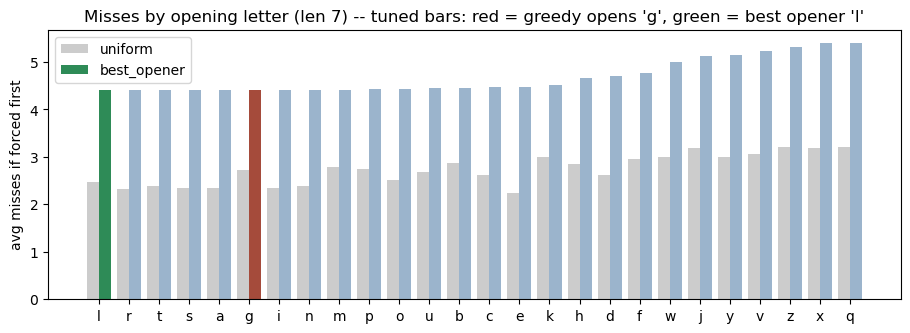

,l,r,t,s,a,g,i,n,m,p,...,h,d,f,w,j,y,v,z,x,q
uniform,2.466703,2.330265,2.381339,2.336040,2.337484,2.715755,2.353366,2.395236,2.789208,2.744631,...,2.841906,2.611983,2.963905,2.998917,3.189857,2.998917,3.054322,3.201047,3.190399,3.204476
best_opener,4.405139,4.405150,4.405171,4.405835,4.410402,4.410402,4.410402,4.410402,4.415106,4.421169,...,4.665230,4.714639,4.762610,4.996244,5.120982,5.151030,5.229241,5.322195,5.406673,5.408799


In [23]:
# the three lenses: uniform baseline, then the two guessers on the tuned distribution
go = game.greedy_first_letter(f)                 # greedy's opener on f
print(f'uniform     : avg {game.average_misses(None):.4f}  (opens {game.greedy_first_letter(None)!r})')
print(f'pure greedy : avg {game.average_misses(f):.4f}  (opens {go!r})')
print(f'best opener : avg {bo:.4f}  (opens {bo_letter!r})')

# Mode B -- misses if each letter is forced first: uniform vs the tuned distribution;
# the tuned bars mark greedy's opener (red) and the best opener (green)
mbu = pd.Series(game.misses_by_starting_letter(None))
mba = pd.Series(game.misses_by_starting_letter(f))
order = list(mba.sort_values().index)
x = np.arange(len(order)); w = 0.4
adv_colors = ['#9bb4cc'] * len(order)
adv_colors[order.index(go)] = '#a54b3b'          # red = greedy opens here
adv_colors[order.index(bo_letter)] = '#2e8b57'   # green = best opener
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(x - w / 2, mbu[order].values, w, label='uniform', color='#cccccc')
ax.bar(x + w / 2, mba[order].values, w, label=OBJECTIVE, color=adv_colors)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel('avg misses if forced first'); ax.legend()
ax.set_title(f'Misses by opening letter (len {LENGTH}) -- tuned bars: '
             f'red = greedy opens {go!r}, green = best opener {bo_letter!r}')
plt.show()
pd.DataFrame({'uniform': mbu[order], OBJECTIVE: mba[order]}).T

## Per-word difficulty: uniform vs greedy vs best opener

All three lenses, frequency-weighted (uniform weights each word equally; the two
tuned lenses weight by `f`; each normalized to a share of total weight).

weighted avg misses -- uniform 2.2379   pure greedy 4.4104   best opener 4.4051


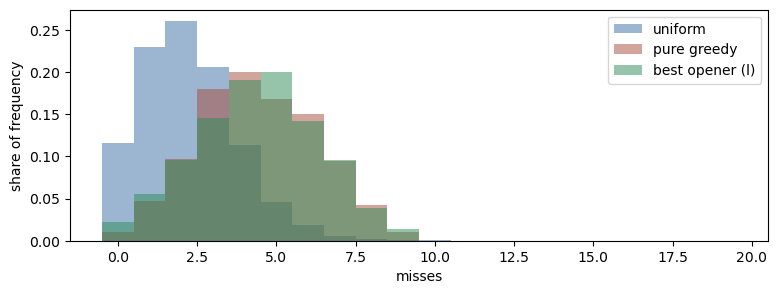

hardest words (pure greedy) under this distribution:


,word,freq,misses_uniform,misses_greedy,misses_best_opener
0,yielded,0.0,3,19,19
1,relayed,0.0,3,19,19
2,relaxed,0.0,2,18,18
3,wielded,0.0,2,18,18
4,wettest,0.0,0,17,17
5,sayings,0.0,2,17,17
6,tweeter,0.0,1,17,17
7,sweeter,0.0,2,16,16
8,twitter,0.0,6,16,16
9,whereby,0.0,2,16,16


In [24]:
upm = game.per_word_misses(None)                 # uniform baseline (pure greedy)
gpm = game.per_word_misses(f)                    # pure greedy on the tuned distribution
bpm = game.per_word_misses(f, opener=bo_letter)  # best opener on the tuned distribution
words = pd.DataFrame({'word': game.words, 'freq': f,
                      'misses_uniform':     upm.astype(int),
                      'misses_greedy':      gpm.astype(int),
                      'misses_best_opener': bpm.astype(int)})

print(f'weighted avg misses -- uniform {game.average_misses(None):.4f}   '
      f'pure greedy {game.average_misses(f):.4f}   best opener {bo:.4f}')

bins = range(0, int(max(upm.max(), gpm.max(), bpm.max())) + 2)
fig, ax = plt.subplots(figsize=(9, 3))
for pwm, wt, name, color in [(upm, None, 'uniform',                    '#3b6ea5'),
                             (gpm, f,    'pure greedy',                '#a54b3b'),
                             (bpm, f,    f'best opener ({bo_letter})', '#2e8b57')]:
    ax.hist(pwm, bins=bins, weights=wt, density=True,
            alpha=0.5, label=name, color=color, align='left')
ax.set_xlabel('misses'); ax.set_ylabel('share of frequency'); ax.legend()
plt.show()

print('hardest words (pure greedy) under this distribution:')
words.sort_values('misses_greedy', ascending=False).head(15).reset_index(drop=True)

In [25]:
# The adversary zeros out many words (freq 0) -- those don't count toward its
# average. Hardest words it actually KEEPS (nonzero frequency), with both guessers:
kept = words[words.freq > 0]
print(f'{len(kept)} of {len(words)} words kept (nonzero frequency)')
kept.sort_values('misses_best_opener', ascending=False).head(15).reset_index(drop=True)

358 of 5541 words kept (nonzero frequency)


,word,freq,misses_uniform,misses_greedy,misses_best_opener
0,hurting,131072.0,10,8,9
1,webbing,294912.0,6,9,9
2,bumping,65536.0,5,9,9
3,purring,131072.0,8,9,9
4,veering,60928.0,4,8,9
5,jutting,524288.0,9,8,8
6,serving,131072.0,5,8,8
7,seeking,278528.0,5,7,8
8,revving,131072.0,5,8,8
9,pushing,131072.0,4,8,8


## Trace a word: uniform vs greedy vs best opener

The guess sequence for one word under each lens (`+` = hit, `-` = miss). On the
tuned distribution greedy opens with `go` and the best-opener guesser with
`bo_letter`; the uniform lens is the normal-game baseline.

In [26]:
# hardest word (pure greedy) the adversary actually KEEPS; or set WORD = 'bench'
nz = np.flatnonzero(f > 0)
WORD = game.words[nz[gpm[nz].argmax()]]
print(WORD)
for name, fr, kw in [('uniform', None, {}),
                     (f'greedy (opens {go})',      f, {}),
                     (f'best opener (opens {bo_letter})', f, {'opener': bo_letter})]:
    hits = game.trace(WORD, fr, **kw)
    seq = '  '.join(f'{l}{"+" if h else "-"}' for l, h in hits)
    print(f'{name:>26}  ({sum(1 for _, h in hits if not h)} misses):  {seq}')

bumping
                   uniform  (5 misses):  e-  i+  n+  g+  a-  o-  u+  s-  c-  p+  m+  b+
          greedy (opens g)  (9 misses):  g+  i+  n+  a-  o-  u+  c-  b+  t-  d-  z-  k-  h-  r-  m+  p+
     best opener (opens l)  (9 misses):  l-  g+  i+  n+  a-  o-  u+  c-  b+  t-  d-  z-  h-  r-  m+  p+
